# Classification Track — Notebook 11
# 3. Data Quality Audit

**Input:** `artifacts/clf_10_raw.joblib`
**Output:** `artifacts/clf_11_audited.joblib`

---

### Purpose

Establish with printed evidence what the Adult dataset contains, and in
particular:

1. Where the missing values are, and whether the missingness is random.
2. Whether duplicate records exist.
3. Whether any category values are invalid or unexpected.
4. What the class distribution looks like, and **whether class imbalance
   exists** — a question the rubric asks us to address explicitly.

This dataset is considerably messier than the Seoul bike data, which makes
the audit more consequential.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    audit_table,
    load_artifact,
    save_artifact,
    save_figure,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

adult_df = load_artifact("clf_10_raw")
TARGET = "income"
POSITIVE_CLASS = ">50K"

numeric_cols = adult_df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in adult_df.columns if c not in numeric_cols + [TARGET]]

print(f"\nShape: {adult_df.shape}")
print(f"Numeric columns     ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

[loaded] artifacts/clf_10_raw.joblib

Shape: (48842, 15)
Numeric columns     (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns (8): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


---
## 3.1 Missing values — counts and percentages

In [2]:
missing_report = pd.DataFrame({
    "Missing count": adult_df.isna().sum(),
    "Missing %": (100 * adult_df.isna().mean()).round(3),
}).sort_values("Missing count", ascending=False)

section("MISSING VALUE REPORT")
print(missing_report.to_string())

total_missing = int(adult_df.isna().sum().sum())
rows_with_any = int(adult_df.isna().any(axis=1).sum())
print(f"\nTotal missing cells        : {total_missing:,} of "
      f"{adult_df.size:,} ({100 * total_missing / adult_df.size:.2f}%)")
print(f"Rows with at least one gap : {rows_with_any:,} "
      f"({100 * rows_with_any / len(adult_df):.2f}% of all rows)")
print(f"Rows that are fully complete: {len(adult_df) - rows_with_any:,}")

MISSING VALUE REPORT
                Missing count  Missing %
occupation               2809      5.751
workclass                2799      5.731
native-country            857      1.755
fnlwgt                      0      0.000
education                   0      0.000
education-num               0      0.000
age                         0      0.000
marital-status              0      0.000
relationship                0      0.000
sex                         0      0.000
race                        0      0.000
capital-gain                0      0.000
capital-loss                0      0.000
hours-per-week              0      0.000
income                      0      0.000

Total missing cells        : 6,465 of 732,630 (0.88%)
Rows with at least one gap : 3,620 (7.41% of all rows)
Rows that are fully complete: 45,222


**Observation.** Exactly three columns have missing values: `occupation`
(5.75%), `workclass` (5.73%) and `native-country` (1.76%). In total 6,465 cells
are missing — under 1% of the table — but they are concentrated in 3,620 rows,
so **7.41% of all records have at least one gap**.

**Interpretation.** These would all have been invisible had we not passed
`na_values="?"` in Notebook 10. Pandas would have reported a complete dataset
and every model would have treated `"?"` as a genuine employment category.
This is the single most important reason the audit step exists.

Before deciding how to treat them, we need to know **why** they are missing.

### Is the missingness random, or does it carry information?

In [3]:
section("OVERLAP BETWEEN workclass AND occupation MISSINGNESS")
both_missing = int((adult_df["workclass"].isna() & adult_df["occupation"].isna()).sum())
wc_only = int((adult_df["workclass"].isna() & adult_df["occupation"].notna()).sum())
occ_only = int((adult_df["workclass"].notna() & adult_df["occupation"].isna()).sum())
print(f"Both missing together      : {both_missing:,}")
print(f"workclass missing alone    : {wc_only:,}")
print(f"occupation missing alone   : {occ_only:,}")
print(f"\nOf the {int(adult_df['workclass'].isna().sum()):,} rows missing workclass, "
      f"{100 * both_missing / adult_df['workclass'].isna().sum():.1f}% are also missing occupation.")

OVERLAP BETWEEN workclass AND occupation MISSINGNESS
Both missing together      : 2,799
workclass missing alone    : 0
occupation missing alone   : 10

Of the 2,799 rows missing workclass, 100.0% are also missing occupation.


In [4]:
section("WHO ARE THE PEOPLE WITH MISSING EMPLOYMENT DATA?")
missing_mask = adult_df["workclass"].isna()

profile = pd.DataFrame({
    "Missing workclass": adult_df.loc[missing_mask, ["age", "hours-per-week",
                                                     "education-num"]].mean(),
    "Complete records": adult_df.loc[~missing_mask, ["age", "hours-per-week",
                                                     "education-num"]].mean(),
}).round(2)
print(profile.to_string())

print("\nIncome rate among each group:")
print(f"  Missing workclass : "
      f"{100 * (adult_df.loc[missing_mask, TARGET] == POSITIVE_CLASS).mean():.2f}% earn >50K")
print(f"  Complete records  : "
      f"{100 * (adult_df.loc[~missing_mask, TARGET] == POSITIVE_CLASS).mean():.2f}% earn >50K")

print("\nWhat occupation do they report when workclass is missing?")
print(adult_df.loc[missing_mask, "occupation"].value_counts(dropna=False).head().to_string())

WHO ARE THE PEOPLE WITH MISSING EMPLOYMENT DATA?
                Missing workclass  Complete records
age                         40.14             38.55
hours-per-week              31.81             40.95
education-num                9.25             10.13

Income rate among each group:
  Missing workclass : 9.47% earn >50K
  Complete records  : 24.81% earn >50K

What occupation do they report when workclass is missing?
occupation
NaN    2799


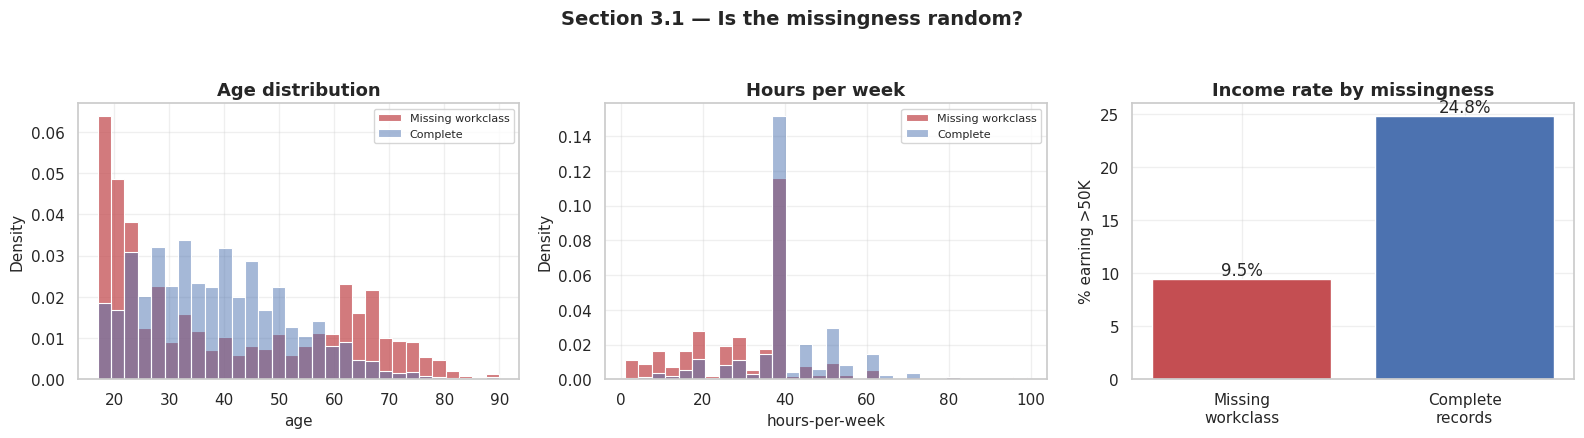

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.histplot(adult_df.loc[missing_mask, "age"], bins=30, ax=axes[0],
             color="#C44E52", stat="density", label="Missing workclass")
sns.histplot(adult_df.loc[~missing_mask, "age"], bins=30, ax=axes[0],
             color="#4C72B0", stat="density", alpha=0.5, label="Complete")
axes[0].set_title("Age distribution")
axes[0].legend(fontsize=8)

sns.histplot(adult_df.loc[missing_mask, "hours-per-week"], bins=30, ax=axes[1],
             color="#C44E52", stat="density", label="Missing workclass")
sns.histplot(adult_df.loc[~missing_mask, "hours-per-week"], bins=30, ax=axes[1],
             color="#4C72B0", stat="density", alpha=0.5, label="Complete")
axes[1].set_title("Hours per week")
axes[1].legend(fontsize=8)

rates = pd.Series({
    "Missing\nworkclass": 100 * (adult_df.loc[missing_mask, TARGET] == POSITIVE_CLASS).mean(),
    "Complete\nrecords": 100 * (adult_df.loc[~missing_mask, TARGET] == POSITIVE_CLASS).mean(),
})
axes[2].bar(rates.index, rates.values, color=["#C44E52", "#4C72B0"])
axes[2].bar_label(axes[2].containers[0], fmt="%.1f%%")
axes[2].set_ylabel("% earning >50K")
axes[2].set_title("Income rate by missingness")

fig.suptitle("Section 3.1 — Is the missingness random?", y=1.04,
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("clf_missingness_profile", fig)
plt.show()

**Observation.** The missingness is clearly **not** random:

* `workclass` and `occupation` are missing **together in every single case** —
  all 2,799 rows missing `workclass` are also missing `occupation`, and not one
  row is missing `workclass` alone. They are not two independent gaps but one.
* People with missing employment data are slightly older (mean age 40.1 vs
  38.6) and work **substantially fewer hours** (31.8 vs 40.9 per week).
* Only **9.5% of them earn >50K**, against **24.8%** of complete records — less
  than half the rate.

**Interpretation.** This is a recognisable group: **people who are not
currently employed** — largely retirees, and some who have never worked. A
census respondent with no job has no workclass and no occupation to report, so
the field is blank. The gap is a fact about their employment status, not a
recording error.

In the standard terminology this is **MAR / MNAR** (missing at random given
other variables, arguably not at random), not MCAR. The practical consequence
is important and shapes Notebook 13:

> **Deleting these rows would delete a distinct and predictable population.**
> Imputing "Private" as the most common workclass would assert that a retiree
> works in the private sector — a claim the data contradicts.

Notebook 13 therefore treats the gap as its own category rather than filling
or dropping it, and §5 there sets out the reasoning in full.

---
## 3.2 Duplicate rows

In [6]:
full_dupes = int(adult_df.duplicated().sum())
dupes_excl_weight = int(adult_df.drop(columns=["fnlwgt"]).duplicated().sum())

section("DUPLICATE CHECK")
print(f"Fully identical rows (all 15 columns)      : {full_dupes:,}")
print(f"Identical ignoring the survey weight fnlwgt: {dupes_excl_weight:,}")
print(f"As a share of the dataset                  : "
      f"{100 * full_dupes / len(adult_df):.3f}%")

if full_dupes:
    print("\nExample of a duplicated record:")
    dup_mask = adult_df.duplicated(keep=False)
    example = adult_df[dup_mask].sort_values(list(adult_df.columns)).head(2)
    print(example.to_string(index=False))

DUPLICATE CHECK
Fully identical rows (all 15 columns)      : 52
Identical ignoring the survey weight fnlwgt: 6,374
As a share of the dataset                  : 0.106%

Example of a duplicated record:
 age workclass  fnlwgt education  education-num marital-status occupation relationship  race    sex  capital-gain  capital-loss  hours-per-week native-country income
  17   Private  153021      12th              8  Never-married      Sales    Own-child White Female             0             0              20  United-States  <=50K
  17   Private  153021      12th              8  Never-married      Sales    Own-child White Female             0             0              20  United-States  <=50K


**Observation.** 52 rows (0.106%) are identical across all 15 columns. Ignoring
the survey weight `fnlwgt`, the count rises to 6,374 — but `fnlwgt` is a
continuous sampling weight, so two people sharing all 14 substantive attributes
while differing in it is entirely expected.

**Interpretation.** These are almost certainly **coincidental collisions**
rather than data-entry errors. The dataset has only 15 attributes, most of them
coarse categories, describing nearly 49,000 people. Two different 25-year-old
private-sector clerical workers with a high-school education working 40 hours a
week and earning under 50K will produce identical rows — they are two real,
distinct people who happen to share every recorded attribute.

This is a materially different situation from the bike data, where
`(Date, Hour)` was a true primary key and any duplicate would have been an
error. Here there is no identifier, so uniqueness is not expected.

**Decision:** keep them. Removing them would discard real survey respondents
and subtly distort the class proportions. The count is a fraction of a percent,
so the choice has negligible effect either way — but the reasoning matters more
than the magnitude. Notebook 13 records this decision alongside the others.

---
## 3.3 Invalid or unexpected categories

In [7]:
for col in categorical_cols:
    section(f"{col}  —  {adult_df[col].nunique()} distinct value(s)")
    counts = adult_df[col].value_counts(dropna=False)
    pct = (100 * adult_df[col].value_counts(dropna=False, normalize=True)).round(2)
    table = pd.DataFrame({"Count": counts, "Percent": pct})
    print(table.head(12).to_string())
    if len(table) > 12:
        print(f"   ... and {len(table) - 12} more categories")
    print()

workclass  —  8 distinct value(s)
                  Count  Percent
workclass                       
Private           33906    69.42
Self-emp-not-inc   3862     7.91
Local-gov          3136     6.42
NaN                2799     5.73
State-gov          1981     4.06
Self-emp-inc       1695     3.47
Federal-gov        1432     2.93
Without-pay          21     0.04
Never-worked         10     0.02

education  —  16 distinct value(s)
              Count  Percent
education                   
HS-grad       15784    32.32
Some-college  10878    22.27
Bachelors      8025    16.43
Masters        2657     5.44
Assoc-voc      2061     4.22
11th           1812     3.71
Assoc-acdm     1601     3.28
10th           1389     2.84
7th-8th         955     1.96
Prof-school     834     1.71
9th             756     1.55
12th            657     1.35
   ... and 4 more categories

marital-status  —  7 distinct value(s)
                       Count  Percent
marital-status                       
Married-civ-spou

In [8]:
section("CHECKS FOR COMMON CATEGORY PROBLEMS")
issues = []
for col in categorical_cols:
    values = adult_df[col].dropna().astype(str)
    if (values != values.str.strip()).any():
        issues.append(f"{col}: values with leading/trailing whitespace")
    lowered = values.str.lower()
    if lowered.nunique() != values.nunique():
        issues.append(f"{col}: case-inconsistent duplicates (e.g. 'Private' vs 'private')")
    if values.isin(["?", "unknown", "Unknown", "NA", "N/A", "-", "none"]).any():
        issues.append(f"{col}: residual placeholder strings still present")

print("\n".join(issues) if issues else "No whitespace, case-inconsistency or "
                                       "residual placeholder problems found.")

# Rare categories can break a naive train/test split.
section("RARE CATEGORIES (fewer than 30 rows)")
for col in categorical_cols:
    counts = adult_df[col].value_counts()
    rare = counts[counts < 30]
    if len(rare):
        print(f"{col}: {len(rare)} rare categories → {dict(rare)}")

CHECKS FOR COMMON CATEGORY PROBLEMS


No whitespace, case-inconsistency or residual placeholder problems found.
RARE CATEGORIES (fewer than 30 rows)
workclass: 2 rare categories → {'Without-pay': np.int64(21), 'Never-worked': np.int64(10)}
occupation: 1 rare categories → {'Armed-Forces': np.int64(15)}


native-country: 9 rare categories → {'Cambodia': np.int64(28), 'Trinadad&Tobago': np.int64(27), 'Laos': np.int64(23), 'Yugoslavia': np.int64(23), 'Outlying-US(Guam-USVI-etc)': np.int64(23), 'Scotland': np.int64(21), 'Honduras': np.int64(20), 'Hungary': np.int64(19), 'Holand-Netherlands': np.int64(1)}


**Observation.** No whitespace problems, no case inconsistencies, no residual
`?` strings — the `skipinitialspace=True` and `na_values="?"` arguments from
Notebook 10 did their job. However, several columns contain **very rare
categories**: `workclass` has `Without-pay` (21 rows) and `Never-worked` (10),
`occupation` has `Armed-Forces` (15), and `native-country` spreads 41 values
across the data with a long tail of small counts.

**Interpretation.** Rare categories create a concrete risk: a category present
in the test set but absent from the training set would crash a naive
one-hot encoder. Our pipeline in Notebook 13 uses
`OneHotEncoder(handle_unknown="ignore")`, which maps an unseen category to an
all-zero row instead of raising an error. This is not a formality — with 41
countries and a random split, an unseen level is genuinely likely.

---
## 3.4 Suspicious numeric values

In [9]:
section("NUMERIC RANGE CHECKS")
print(adult_df[numeric_cols].describe().T.round(2).to_string())

print("\nZero-inflation and top-coding:")
for col in ["capital-gain", "capital-loss"]:
    zero_pct = 100 * (adult_df[col] == 0).mean()
    print(f"  {col:<14} {zero_pct:.2f}% are exactly 0")

top_coded = int((adult_df["capital-gain"] == 99999).sum())
print(f"\n  capital-gain == 99999 : {top_coded:,} rows "
      f"({100 * top_coded / len(adult_df):.2f}%)")
print(f"  Of those, {100 * (adult_df.loc[adult_df['capital-gain'] == 99999, TARGET] == POSITIVE_CLASS).mean():.1f}% earn >50K")
print(f"  Next highest capital-gain value below 99999: "
      f"{adult_df.loc[adult_df['capital-gain'] < 99999, 'capital-gain'].max():,}")

print(f"\n  hours-per-week == 99  : {int((adult_df['hours-per-week'] == 99).sum()):,} rows")
print(f"  hours-per-week <= 5   : {int((adult_df['hours-per-week'] <= 5).sum()):,} rows")
print(f"  age >= 90             : {int((adult_df['age'] >= 90).sum()):,} rows "
      f"(90 appears to be a top-coded ceiling)")

NUMERIC RANGE CHECKS
                  count       mean        std      min       25%       50%       75%        max
age             48842.0      38.64      13.71     17.0      28.0      37.0      48.0       90.0
fnlwgt          48842.0  189664.13  105604.03  12285.0  117550.5  178144.5  237642.0  1490400.0
education-num   48842.0      10.08       2.57      1.0       9.0      10.0      12.0       16.0
capital-gain    48842.0    1079.07    7452.02      0.0       0.0       0.0       0.0    99999.0
capital-loss    48842.0      87.50     403.00      0.0       0.0       0.0       0.0     4356.0
hours-per-week  48842.0      40.42      12.39      1.0      40.0      40.0      45.0       99.0

Zero-inflation and top-coding:
  capital-gain   91.74% are exactly 0
  capital-loss   95.33% are exactly 0

  capital-gain == 99999 : 244 rows (0.50%)
  Of those, 100.0% earn >50K
  Next highest capital-gain value below 99999: 41,310

  hours-per-week == 99  : 137 rows
  hours-per-week <= 5   : 318 rows
 

**Observation.**

* `capital-gain` and `capital-loss` are zero for the overwhelming majority of
  respondents.
* 244 records carry `capital-gain == 99999`, and the next highest value in the
  data is 41,310 — a gap of nearly 60,000 with nothing in between.
  **100% of people with that value earn >50K.**
* `age` stops abruptly at 90, and `hours-per-week` at 99.

**Interpretation.** These are **top-coded** values, a standard census
disclosure-protection practice: values above a ceiling are replaced by the
ceiling so individuals cannot be identified from unusual entries. `99999` does
not mean "$99,999 of capital gains"; it means "a lot". Likewise age 90 means
"90 or older".

**Decision: leave them as they are, and do not treat them as outliers.**
Three reasons:

1. They are **genuine encoded information**, not errors. Removing them would
   delete the highest earners — the minority class we most need to predict.
2. **The models we use are mostly untroubled by them.** Decision trees split on
   rank order, so the exact magnitude of 99999 is irrelevant. For Logistic
   Regression, KNN and SVC the `StandardScaler` in the pipeline handles the
   scale.
3. Replacing them with an estimate would be **inventing data**.

We do note one consequence: `capital-gain` is such a strong signal for the
>50K class that models may lean on it heavily, which we check in Notebook 14.

---
## 3.5 Target distribution and class imbalance

The rubric asks us to discuss class imbalance explicitly. This section does so
with measurements rather than assertion.

In [10]:
class_counts = adult_df[TARGET].value_counts()
class_pct = adult_df[TARGET].value_counts(normalize=True).mul(100).round(2)

target_table = pd.DataFrame({"Count": class_counts, "Percent": class_pct})

section("TARGET CLASS DISTRIBUTION")
print(target_table.to_string())

majority = class_counts.idxmax()
minority = class_counts.idxmin()
imbalance_ratio = class_counts.max() / class_counts.min()

print(f"\nMajority class      : '{majority}'  ({class_counts.max():,} rows)")
print(f"Minority class      : '{minority}'  ({class_counts.min():,} rows)")
print(f"Imbalance ratio     : {imbalance_ratio:.2f} : 1")
print(f"Minority proportion : {100 * class_counts.min() / len(adult_df):.2f}%")

TARGET CLASS DISTRIBUTION
        Count  Percent
income                
<=50K   37155    76.07
>50K    11687    23.93

Majority class      : '<=50K'  (37,155 rows)
Minority class      : '>50K'  (11,687 rows)
Imbalance ratio     : 3.18 : 1
Minority proportion : 23.93%


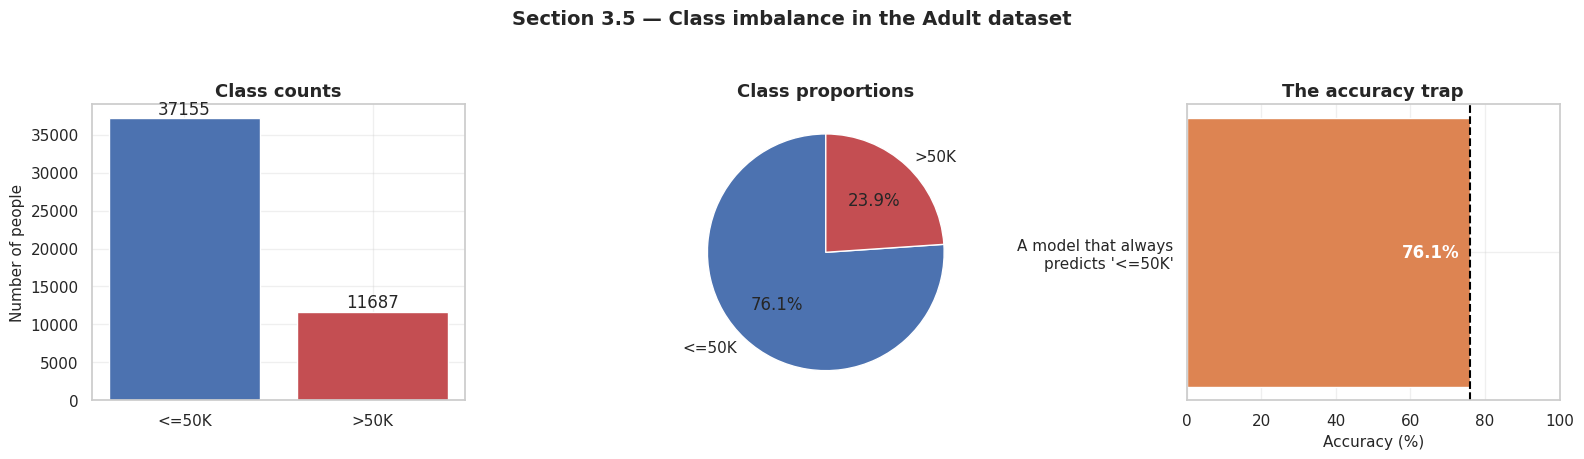

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

bars = axes[0].bar(target_table.index, target_table["Count"],
                   color=["#4C72B0", "#C44E52"])
axes[0].bar_label(bars, fmt="%,d" if False else "%d")
axes[0].set_ylabel("Number of people")
axes[0].set_title("Class counts")

axes[1].pie(target_table["Count"], labels=target_table.index, autopct="%1.1f%%",
            colors=["#4C72B0", "#C44E52"], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Class proportions")

baseline_acc = 100 * class_counts.max() / len(adult_df)
axes[2].barh(["A model that always\npredicts '<=50K'"], [baseline_acc], color="#DD8452")
axes[2].set_xlim(0, 100)
axes[2].axvline(baseline_acc, color="black", ls="--")
axes[2].text(baseline_acc - 3, 0, f"{baseline_acc:.1f}%", va="center",
             ha="right", color="white", fontweight="bold")
axes[2].set_xlabel("Accuracy (%)")
axes[2].set_title("The accuracy trap")

fig.suptitle("Section 3.5 — Class imbalance in the Adult dataset",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("clf_class_distribution", fig)
plt.show()

**Observation.** The classes are split **76.07% / 23.93%** — 37,155 people
earning ≤50K against 11,687 earning >50K, an imbalance ratio of **3.18 : 1**.

**Interpretation — does class imbalance exist, and does it matter?**

**Yes, imbalance exists, but it is moderate rather than severe.** A 3.2 : 1
ratio is nothing like the 1000 : 1 seen in fraud detection. It is enough to
distort naive evaluation, but not enough to make the minority class
unlearnable. That distinction determines our response, and it is why we do
**not** apply SMOTE or class re-weighting: those techniques address severe
imbalance, and applying them here would add complexity and distort the
calibrated probabilities for a problem that does not require it.

What the imbalance **does** demand is care in three specific places:

1. **Accuracy alone is misleading.** A model that predicts `<=50K` for every
   single person — learning absolutely nothing — scores **76.07% accuracy**.
   That is the third panel above. Any accuracy figure in this project must be
   read against that 76% floor, not against 0%.
2. **Weighted F1 is the more informative headline metric**, which is why the
   guidelines mandate it. F1 is the harmonic mean of precision and recall, and
   the harmonic mean is dragged down by whichever is worse. The always-`<=50K`
   model scores **0.0000 F1 on the >50K class** and a weighted F1 of **0.6573**
   against its 0.7607 accuracy — a full 10-point gap between the two metrics
   for the same predictions. F1 catches exactly the failure accuracy conceals.
3. **The split must be stratified.** With 24% minority, a careless random split
   could give train and test noticeably different class balances, making the
   comparison between models unreliable. Notebook 13 uses
   `stratify=y` for precisely this reason.

In [12]:
section("THE 'ALWAYS PREDICT THE MAJORITY' BASELINE")
from sklearn.metrics import accuracy_score, f1_score  # noqa: E402

y_true = (adult_df[TARGET] == POSITIVE_CLASS).astype(int)
y_naive = np.zeros(len(y_true), dtype=int)   # predict '<=50K' for everyone

print(f"Accuracy    : {accuracy_score(y_true, y_naive):.4f}  "
      f"← looks respectable, but the model has learned nothing")
print(f"Weighted F1 : {f1_score(y_true, y_naive, average='weighted', zero_division=0):.4f}")
print(f"F1 on >50K  : {f1_score(y_true, y_naive, pos_label=1, zero_division=0):.4f}  "
      f"← the metric that exposes the failure")
print("\nEvery model in Notebook 14 must be judged against these numbers.")

THE 'ALWAYS PREDICT THE MAJORITY' BASELINE
Accuracy    : 0.7607  ← looks respectable, but the model has learned nothing
Weighted F1 : 0.6573
F1 on >50K  : 0.0000  ← the metric that exposes the failure

Every model in Notebook 14 must be judged against these numbers.


---
## 3.6 Consolidated audit table

In [13]:
audit = audit_table(adult_df)
save_table(audit, "clf_data_quality_audit")
audit

[saved]  outputs/clf_data_quality_audit.csv


,Column,Dtype,Missing,Missing %,Unique,Example value
0,age,int64,0,0.000,74,39
1,workclass,str,2799,5.731,8,State-gov
2,fnlwgt,int64,0,0.000,28523,77516
3,education,str,0,0.000,16,Bachelors
4,education-num,int64,0,0.000,16,13
5,marital-status,str,0,0.000,7,Never-married
6,occupation,str,2809,5.751,14,Adm-clerical
7,relationship,str,0,0.000,6,Not-in-family
8,race,str,0,0.000,5,White
9,sex,str,0,0.000,2,Male


---
## 3.7 Audit summary

| Check | Result | Action |
|---|---|---|
| Missing values | 3 columns; 3,620 rows (7.41%) affected | Treat as a category — **not** random (§3.1) |
| Missingness pattern | `workclass` + `occupation` missing together; older, fewer hours, lower income | Encode as `"Unknown"` in Notebook 13 |
| Duplicate rows | 52 rows (0.106%), all plausible coincidences | Keep; no identifier exists, so uniqueness is not expected |
| Invalid categories | None after correct parsing | None |
| Rare categories | `native-country` and `workclass` have very rare levels | `handle_unknown="ignore"` in the encoder |
| Top-coded values | `capital-gain` 99999 (244 rows), `age` 90, `hours` 99 | Keep — genuine encoded information, not errors |
| Zero-inflation | `capital-gain` / `capital-loss` mostly 0 | Keep; consider a binary flag in feature engineering |
| Class imbalance | 76.07% / 23.93%, ratio 3.18 : 1 | Stratified split; weighted F1 as headline metric |
| Naive baseline | 0.7607 accuracy / 0.6573 weighted F1 for a model that learns nothing | Every result must be read against this floor |

---
## Handover to Notebook 12

In [14]:
save_artifact(adult_df, "clf_11_audited")

print("\nNotebook 11 complete.")
print("Next: 12_classification_eda.ipynb")

[saved]  artifacts/clf_11_audited.joblib

Notebook 11 complete.
Next: 12_classification_eda.ipynb
